# Customer Segmentation Using RFM Analysis

## 1. Data Loading and Inspection

Load the cleaned e-commerce dataset and inspect its structure before calculating Recency, Frequency, and Monetary metrics.

In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("../Dataset/Cleaned/ecommerce_sales_customer_cleaned.csv")

# Convert date columns
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

# Inspect dataset
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset Shape: (49885, 18)

Columns:
['OrderID', 'OrderDate', 'CustomerID', 'CustomerRegistrationDate', 'ProductID', 'ProductName', 'Category', 'Quantity', 'UnitPrice', 'DiscountPct', 'GrossSales', 'DiscountAmount', 'NetSales', 'Region', 'Country', 'PaymentMethod', 'ReturnStatus', 'ReturnDate']


,OrderID,OrderDate,CustomerID,CustomerRegistrationDate,ProductID,ProductName,Category,Quantity,UnitPrice,DiscountPct,GrossSales,DiscountAmount,NetSales,Region,Country,PaymentMethod,ReturnStatus,ReturnDate
0,ORD003508,2025-02-25,CUST07492,2024-07-08,P012,Kitchen Organizer,Home & Kitchen,4,33.21,0.0,132.84,0.00,132.84,Europe,Spain,Gift Card,Not Returned,NaN
1,ORD008536,2025-01-25,CUST06763,2022-08-07,P015,Water Bottle,Sports,3,17.01,20.0,51.03,10.21,40.82,Asia Pacific,India,Debit Card,Not Returned,NaN
2,ORD009501,2025-06-16,CUST07225,2023-06-30,P012,Kitchen Organizer,Home & Kitchen,5,35.11,0.0,175.55,0.00,175.55,Europe,Germany,Digital Wallet,Not Returned,NaN
3,ORD015712,2025-11-12,CUST04817,2024-08-18,P016,Face Moisturizer,Beauty,5,25.10,0.0,125.50,0.00,125.50,Latin America,Chile,Cash on Delivery,Not Returned,NaN
4,ORD003485,2025-02-04,CUST00134,2022-08-01,P003,Smart Watch,Electronics,1,110.82,10.0,110.82,11.08,99.74,Europe,Spain,Credit Card,Not Returned,NaN


In [2]:
print("Unique Customers:", df["CustomerID"].nunique())
print("Unique Orders:", df["OrderID"].nunique())
print("Date Range:", df["OrderDate"].min(), "to", df["OrderDate"].max())
print("Missing Customer IDs:", df["CustomerID"].isna().sum())

Unique Customers: 6985
Unique Orders: 20745
Date Range: 2024-01-01 00:00:00 to 2026-06-30 00:00:00
Missing Customer IDs: 0


## 2. RFM Metrics Calculation

Calculate customer-level Recency, Frequency, and Monetary values:

- Recency: Days since the customer's most recent purchase.
- Frequency: Number of distinct orders placed by the customer.
- Monetary: Total net sales generated by the customer.

Use the day after the latest transaction date as the reference date.

In [3]:
# Set reference date
reference_date = df["OrderDate"].max() + pd.Timedelta(days=1)

# Aggregate transaction data at customer level
rfm = df.groupby("CustomerID").agg(
    Recency=("OrderDate", lambda x: (reference_date - x.max()).days),
    Frequency=("OrderID", "nunique"),
    Monetary=("NetSales", "sum")
).reset_index()

# Inspect RFM dataset
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,CUST00001,455,4,449.05
1,CUST00002,458,3,878.80
2,CUST00003,181,2,181.49
3,CUST00004,594,2,539.00
4,CUST00005,153,4,989.30


In [4]:
print("RFM Shape:", rfm.shape)

print("\nRFM Summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nUnique Customers:", rfm["CustomerID"].nunique())

RFM Shape: (6985, 4)

RFM Summary:


,Recency,Frequency,Monetary
count,6985.000000,6985.000000,6985.000000
mean,268.935433,2.969936,742.586567
std,219.654154,1.560708,460.208866
min,1.000000,1.000000,32.030000
25%,90.000000,2.000000,391.190000
50%,213.000000,3.000000,660.810000
75%,401.000000,4.000000,1011.820000
max,912.000000,10.000000,3188.620000



Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Unique Customers: 6985


## 3. RFM Scoring

Assign scores from 1 to 5 for each RFM metric using quintile-based ranking.

- Recency: Lower values receive higher scores.
- Frequency: Higher values receive higher scores.
- Monetary: Higher values receive higher scores.

A score of 5 represents the strongest customer behaviour.

In [5]:
# Assign RFM scores using quintiles
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,CUST00001,455,4,449.05,2,4,2,242
1,CUST00002,458,3,878.80,2,3,4,234
2,CUST00003,181,2,181.49,3,1,1,311
3,CUST00004,594,2,539.00,1,1,2,112
4,CUST00005,153,4,989.30,4,4,4,444
5,CUST00006,89,4,941.19,4,4,4,444
6,CUST00007,224,2,256.56,3,1,1,311
7,CUST00009,32,4,796.40,5,4,4,544
8,CUST00010,11,3,449.56,5,3,2,532
9,CUST00011,120,7,1936.75,4,5,5,455


In [6]:
print("Recency Score Distribution:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nFrequency Score Distribution:")
print(rfm["F_Score"].value_counts().sort_index())

print("\nMonetary Score Distribution:")
print(rfm["M_Score"].value_counts().sort_index())

print("\nCombined RFM Scores:")
print(rfm["RFM_Score"].nunique(), "unique combinations")

Recency Score Distribution:
R_Score
1    1397
2    1397
3    1397
4    1397
5    1397
Name: count, dtype: int64

Frequency Score Distribution:
F_Score
1    1397
2    1397
3    1397
4    1397
5    1397
Name: count, dtype: int64

Monetary Score Distribution:
M_Score
1    1397
2    1397
3    1397
4    1397
5    1397
Name: count, dtype: int64

Combined RFM Scores:
114 unique combinations


## 4. Customer Segmentation

Classify customers into business segments based on their Recency, Frequency, and Monetary scores.

The segments identify customers based on purchasing behaviour and help businesses develop targeted retention, engagement, and marketing strategies.

Segmentation rules:

- Champions: High scores across all three RFM metrics.
- Loyal Customers: Frequent purchasers with strong recent activity.
- Potential Loyalists: Recent customers who show purchasing potential.
- Recent Customers: Customers who have purchased recently but have low frequency.
- Cannot Lose Them: Previously valuable customers who have not purchased recently.
- At Risk: Customers with multiple purchases but declining recent activity.
- Hibernating: Customers with low engagement and limited purchasing activity.

In [7]:
# Define customer segmentation rules
def segment_customer(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4 and m >= 3:
        return "Loyal Customers"

    elif r >= 4 and f >= 2 and m >= 2:
        return "Potential Loyalists"

    elif r >= 4 and f == 1:
        return "Recent Customers"

    elif r <= 2 and f >= 4 and m >= 4:
        return "Cannot Lose Them"

    elif r <= 2 and f >= 3:
        return "At Risk"

    else:
        return "Hibernating"


# Apply segmentation rules
rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

# Inspect segmented customers
rfm[[
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary",
    "RFM_Score",
    "Customer_Segment"
]].head(15)

,CustomerID,Recency,Frequency,Monetary,RFM_Score,Customer_Segment
0,CUST00001,455,4,449.05,242,At Risk
1,CUST00002,458,3,878.80,234,At Risk
2,CUST00003,181,2,181.49,311,Hibernating
3,CUST00004,594,2,539.00,112,Hibernating
4,CUST00005,153,4,989.30,444,Champions
5,CUST00006,89,4,941.19,444,Champions
6,CUST00007,224,2,256.56,311,Hibernating
7,CUST00009,32,4,796.40,544,Champions
8,CUST00010,11,3,449.56,532,Potential Loyalists
9,CUST00011,120,7,1936.75,455,Champions


In [8]:
# Count customers in each segment
segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("CustomerID", "nunique"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
    .sort_values("Customer_Count", ascending=False)
)

# Calculate customer percentage
segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"] /
    rfm["CustomerID"].nunique()
) * 100

segment_summary.round(2)

,Customer_Segment,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue,Customer_Percentage
3,Hibernating,2573,418.67,1.70,406.17,1045088.16,36.84
2,Champions,1257,70.34,4.90,1297.47,1630925.02,18.00
5,Potential Loyalists,954,74.67,2.61,660.29,629919.90,13.66
4,Loyal Customers,809,176.45,4.26,1003.61,811924.27,11.58
0,At Risk,703,438.66,2.93,667.29,469106.58,10.06
1,Cannot Lose Them,439,388.89,4.36,1194.62,524436.51,6.28
6,Recent Customers,250,79.07,1.16,302.27,75566.73,3.58


In [9]:
print("Total Customers:", rfm["CustomerID"].nunique())

print(
    "Customers Across All Segments:",
    segment_summary["Customer_Count"].sum()
)

print(
    "Total Segment Revenue:",
    round(segment_summary["Total_Revenue"].sum(), 2)
)

print("\nCustomer Segment Distribution:")
print(
    rfm["Customer_Segment"]
    .value_counts()
)

Total Customers: 6985
Customers Across All Segments: 6985
Total Segment Revenue: 5186967.17

Customer Segment Distribution:
Customer_Segment
Hibernating            2573
Champions              1257
Potential Loyalists     954
Loyal Customers         809
At Risk                 703
Cannot Lose Them        439
Recent Customers        250
Name: count, dtype: int64


## 5. RFM Visualisation

Visualise customer segmentation results to understand the distribution of customers and revenue across different RFM segments.

The visualisations will include:

- Customer count by segment.
- Customer percentage by segment.
- Revenue contribution by segment.

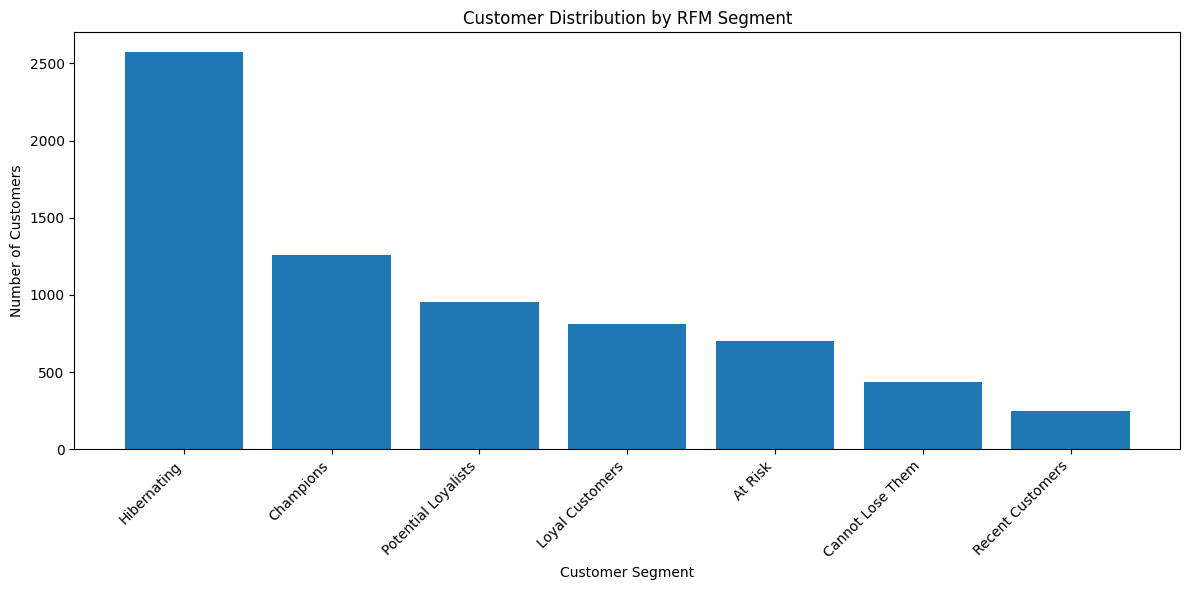

In [10]:
import matplotlib.pyplot as plt

# Sort segments by customer count
segment_counts = segment_summary.sort_values(
    "Customer_Count",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    segment_counts["Customer_Segment"],
    segment_counts["Customer_Count"]
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save chart
plt.savefig(
    "../Screenshots/Plots/13_customer_distribution_by_rfm_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

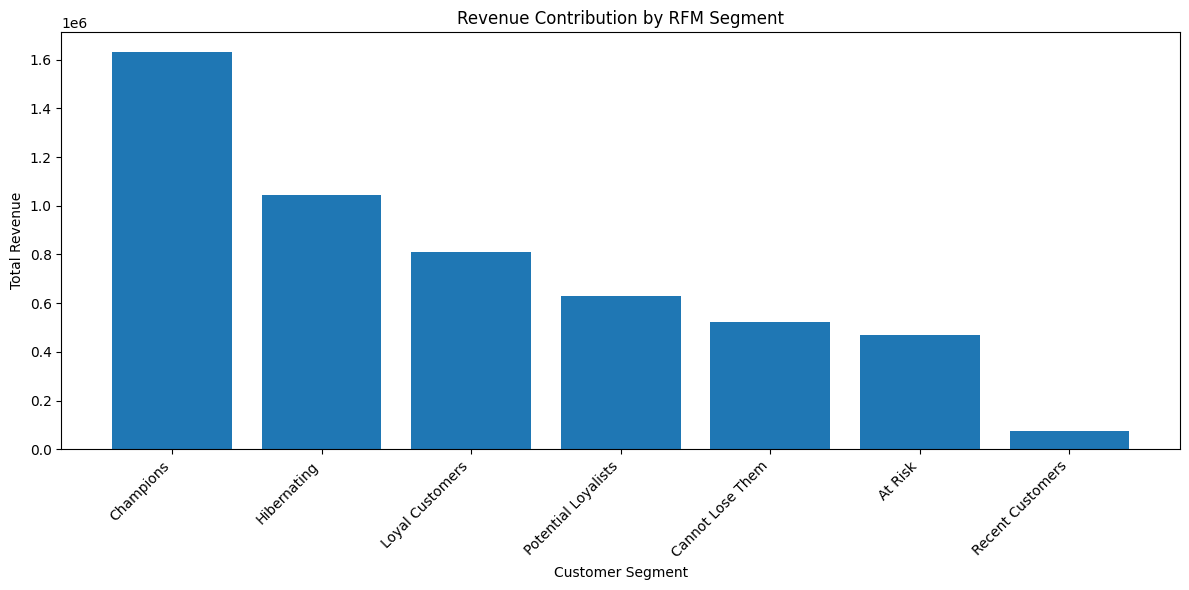

In [11]:
# Sort segments by revenue
revenue_segments = segment_summary.sort_values(
    "Total_Revenue",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    revenue_segments["Customer_Segment"],
    revenue_segments["Total_Revenue"]
)

plt.title("Revenue Contribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save chart
plt.savefig(
    "../Screenshots/Plots/14_revenue_contribution_by_rfm_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

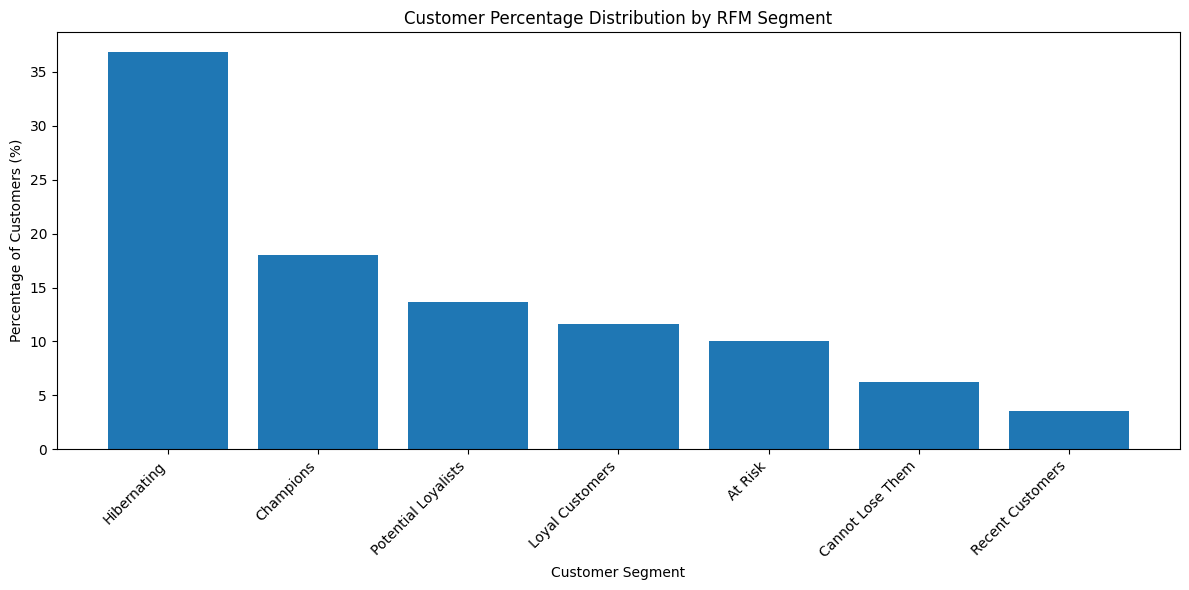

In [12]:
# Sort segments by customer percentage
percentage_segments = segment_summary.sort_values(
    "Customer_Percentage",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    percentage_segments["Customer_Segment"],
    percentage_segments["Customer_Percentage"]
)

plt.title("Customer Percentage Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save chart
plt.savefig(
    "../Screenshots/Plots/15_customer_percentage_by_rfm_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

## 6. Export Customer Segmentation Dataset

Export the final customer-level RFM dataset containing:

- Customer ID
- Recency, Frequency, and Monetary metrics
- RFM scores
- Combined RFM score
- Customer segment classification

The exported dataset can be reused for further analysis and business intelligence reporting.

In [13]:
# Define output file path
output_path = "../Dataset/Cleaned/ecommerce_customer_rfm_segments.csv"

# Export RFM customer segmentation dataset
rfm.to_csv(
    output_path,
    index=False
)

print("Customer segmentation dataset exported successfully!")
print("File:", output_path)
print("Dataset Shape:", rfm.shape)

Customer segmentation dataset exported successfully!
File: ../Dataset/Cleaned/ecommerce_customer_rfm_segments.csv
Dataset Shape: (6985, 9)


In [14]:
# Reload exported dataset
rfm_exported = pd.read_csv(output_path)

print("Exported Dataset Shape:", rfm_exported.shape)

print("\nMissing Values:")
print(rfm_exported.isnull().sum())

print("\nUnique Customers:", rfm_exported["CustomerID"].nunique())

print("\nCustomer Segment Distribution:")
print(rfm_exported["Customer_Segment"].value_counts())

print(
    "\nTotal Monetary Value:",
    round(rfm_exported["Monetary"].sum(), 2)
)

Exported Dataset Shape: (6985, 9)

Missing Values:
CustomerID          0
Recency             0
Frequency           0
Monetary            0
R_Score             0
F_Score             0
M_Score             0
RFM_Score           0
Customer_Segment    0
dtype: int64

Unique Customers: 6985

Customer Segment Distribution:
Customer_Segment
Hibernating            2573
Champions              1257
Potential Loyalists     954
Loyal Customers         809
At Risk                 703
Cannot Lose Them        439
Recent Customers        250
Name: count, dtype: int64

Total Monetary Value: 5186967.17
